# Module 01 — Linear Algebra Refresher (in code)

Linear algebra is the language ML models are written in. You don't need proofs. You need to be fluent with
a handful of operations and to know what they *mean*.

**Learning goals**
- Vectors as data points, plus vector addition and scaling.
- The **dot product** as a weighted sum. This is literally how a linear model makes a prediction.
- **Norms** (length) and **distances** between vectors.
- Matrices, transpose, and the **shape rules** of matrix multiplication.
- `X @ w`: predicting for every sample at once.
- Solving `Xw = y` exactly with an inverse, and approximately with least squares (a preview of linear regression).
- A gentle preview of eigenvectors (used again in PCA, Module 16).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=3, suppress=True)   # tidier printing: 3 decimals, no scientific notation
rng = np.random.default_rng(42)

## 1. Vectors

A vector is an ordered list of numbers. In ML, a vector usually is **one data point**: a house described by
`[size_m2, bedrooms, age_years]` is a vector in 3-D "feature space".

Geometrically, a 2-D vector is an arrow from the origin. Two basic operations:
- **Addition** `u + v`: add element by element. Geometrically, place the arrows tip to tail.
- **Scalar multiplication** `c * v`: stretch (or flip, if c < 0) the arrow.

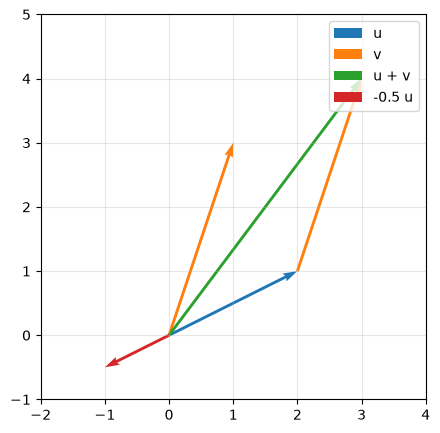

In [2]:
u = np.array([2.0, 1.0])
v = np.array([1.0, 3.0])

fig, ax = plt.subplots(figsize=(5, 5))
def arrow(vec, start=(0, 0), color="k", label=None):
    ax.quiver(*start, *vec, angles="xy", scale_units="xy", scale=1, color=color, label=label)

arrow(u, color="tab:blue", label="u")
arrow(v, color="tab:orange", label="v")
arrow(v, start=u, color="tab:orange")          # v drawn from the tip of u
arrow(u + v, color="tab:green", label="u + v")
arrow(-0.5 * u, color="tab:red", label="-0.5 u")
ax.set_xlim(-2, 4); ax.set_ylim(-1, 5); ax.grid(alpha=0.3); ax.set_aspect("equal"); ax.legend()
plt.show()

## 2. The dot product: the most important operation in ML

$$u \cdot v = \sum_i u_i v_i = u_1 v_1 + u_2 v_2 + \dots$$

**Interpretation 1: a weighted sum.** A linear model predicts a house price as
`price = w1*size + w2*bedrooms + w3*age + b`. That is the dot product `w · x` plus a bias `b`.
Every linear model, logistic regression, SVM and each neuron of a neural network starts with this.

In [3]:
x = np.array([120.0, 3.0, 15.0])         # one house: size, bedrooms, age
w = np.array([2000.0, 10000.0, -1500.0]) # learned weights: what each feature is "worth"
b = 50_000.0                             # bias / intercept: the baseline price

manual = sum(wi * xi for wi, xi in zip(w, x))
print("loop:     ", manual + b)
print("np.dot:   ", np.dot(w, x) + b)
print("@ operator:", w @ x + b)          # @ on two 1-D arrays is the dot product

loop:      297500.0
np.dot:    297500.0
@ operator: 297500.0


**Interpretation 2: similarity / angle.**
$$u \cdot v = \|u\|\,\|v\|\cos\theta$$
- A large positive value means the vectors point the same way.
- Zero means they are perpendicular (**orthogonal**): unrelated.
- A negative value means they point in opposite directions.

Dividing out the lengths gives **cosine similarity** in [-1, 1], which is widely used to compare text documents,
embeddings and recommendations.

In [4]:
def cosine_similarity(a, b):
    return (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

print(cosine_similarity(np.array([1, 0]), np.array([5, 0])))     #  1   same direction
print(cosine_similarity(np.array([1, 0]), np.array([0, 3])))     #  0   orthogonal
print(cosine_similarity(np.array([1, 1]), np.array([-2, -2])))   # -1   opposite

1.0
0.0
-0.9999999999999998


## 3. Norms and distances

A **norm** measures a vector's length.
- **L2 norm (Euclidean)**: $\|v\|_2 = \sqrt{\sum v_i^2}$, the straight-line length.
- **L1 norm (Manhattan)**: $\|v\|_1 = \sum |v_i|$, the length if you can only move along the grid.

The **distance** between two points is the norm of their difference, $\|u - v\|$.
You'll see these again in KNN and k-means (distance) and in Ridge/Lasso regularization (L2/L1 norms of weights).

In [5]:
v = np.array([3.0, -4.0])
print("L2:", np.linalg.norm(v), "=", np.sqrt((v ** 2).sum()))
print("L1:", np.linalg.norm(v, ord=1), "=", np.abs(v).sum())

p, q = np.array([1.0, 2.0]), np.array([4.0, 6.0])
print("Euclidean distance p-q:", np.linalg.norm(p - q))

L2: 5.0 = 5.0
L1: 7.0 = 7.0
Euclidean distance p-q: 5.0


## 4. Matrices and the transpose

A matrix is a 2-D grid of numbers. In ML, the **data matrix** `X` has shape `(n_samples, n_features)`:
each row is one example (a vector) and each column is one feature.

The **transpose** `X.T` swaps rows and columns: shape `(n, d)` becomes `(d, n)`.

In [6]:
X = np.array([[120, 3, 15],
              [ 80, 2, 40],
              [200, 4,  5],
              [ 60, 1, 30]], dtype=float)
print("X shape:", X.shape)
print("X.T shape:", X.T.shape)
print(X.T)

X shape: (4, 3)
X.T shape: (3, 4)
[[120.  80. 200.  60.]
 [  3.   2.   4.   1.]
 [ 15.  40.   5.  30.]]


## 5. Matrix–vector product: predicting for every sample at once

`X @ w` takes the dot product of **every row** of `X` with `w`:

$$ (Xw)_i = x_i \cdot w $$

Shapes: `(n, d) @ (d,) -> (n,)`, giving one prediction per sample. This replaces a loop over the rows.

In [7]:
predictions_loop = np.array([row @ w + b for row in X])
predictions_vec = X @ w + b                  # (4,3) @ (3,) -> (4,), then broadcast + b
print(predictions_loop)
print(predictions_vec)

[297500. 170000. 482500. 135000.]
[297500. 170000. 482500. 135000.]


## 6. Matrix–matrix product and the shape rule

`A @ B` is defined when the **inner dimensions match**:

$$ (n, \mathbf{k}) \; @ \; (\mathbf{k}, m) \;\rightarrow\; (n, m) $$

Entry `(i, j)` of the result is the dot product of **row i of A** and **column j of B**.

Two facts that often surprise people:
- `A @ B` is generally **not** equal to `B @ A` (and one of them may not even be defined).
- `A * B` is **element-wise** multiplication, which is something different. It needs equal or broadcastable shapes.

In [8]:
A = np.array([[1, 2],
              [3, 4],
              [5, 6]])        # (3, 2)
B = np.array([[1, 0, 2],
              [0, 1, 3]])     # (2, 3)

print("A @ B  ->", (A @ B).shape)
print(A @ B)
print("B @ A  ->", (B @ A).shape)
print("entry (0,2) by hand:", A[0] @ B[:, 2])   # row 0 of A · column 2 of B

A @ B  -> (3, 3)
[[ 1  2  8]
 [ 3  4 18]
 [ 5  6 28]]
B @ A  -> (2, 2)
entry (0,2) by hand: 8


A very common pattern is `X.T @ X`, shape `(d, n) @ (n, d) -> (d, d)`. It is a feature-by-feature matrix that
appears in the linear regression formula (Module 07) and, after centering, in the covariance matrix used by PCA (Module 16).

In [9]:
print((X.T @ X).shape)

(3, 3)


## 7. Identity, inverse and solving linear systems

The **identity matrix** `I` is the matrix version of the number 1: `I @ v = v`.

A square matrix `A` may have an **inverse** $A^{-1}$ with $A^{-1}A = I$. It "undoes" `A`.
This lets us solve a system of linear equations. For example:

$$ 2a + 1b = 5 \qquad 1a + 3b = 10 $$

can be written as $A\,\mathbf{x} = \mathbf{y}$ and solved as $\mathbf{x} = A^{-1}\mathbf{y}$.

In [10]:
A = np.array([[2.0, 1.0],
              [1.0, 3.0]])
y = np.array([5.0, 10.0])

A_inv = np.linalg.inv(A)
print("A_inv @ A =\n", A_inv @ A)              # identity (up to rounding)
print("solution via inverse:", A_inv @ y)
print("solution via solve:  ", np.linalg.solve(A, y))   # preferred: faster and more numerically stable

A_inv @ A =
 [[ 1. -0.]
 [ 0.  1.]]
solution via inverse: [1. 3.]
solution via solve:   [1. 3.]


⚠️ Not every matrix has an inverse. If one column is a combination of others (e.g. "price in USD" and
"price in EUR" as two features), the matrix is **singular**. In ML that is called **multicollinearity**,
and it is one reason regularization exists (Module 09).

In [11]:
S = np.array([[1.0, 2.0],
              [2.0, 4.0]])   # row 2 = 2 * row 1
print("determinant:", np.linalg.det(S), "-> 0 means singular, no inverse")
try:
    np.linalg.inv(S)
except np.linalg.LinAlgError as e:
    print("LinAlgError:", e)

determinant: 0.0 -> 0 means singular, no inverse
LinAlgError: Singular matrix


## 8. `Xw = y` with more equations than unknowns: least squares

Real data has many more samples (equations) than features (unknowns), and the points never lie exactly on a
line, so `Xw = y` has **no exact solution**. Instead we find the `w` that makes `Xw` *as close as possible* to `y`,
minimizing $\|Xw - y\|^2$. This is **least squares**, and it *is* linear regression.

Trick: to learn an intercept `b`, add a column of 1s to `X`. Then `b` is just another weight.

estimated [intercept, slope]: [3.537 3.024]


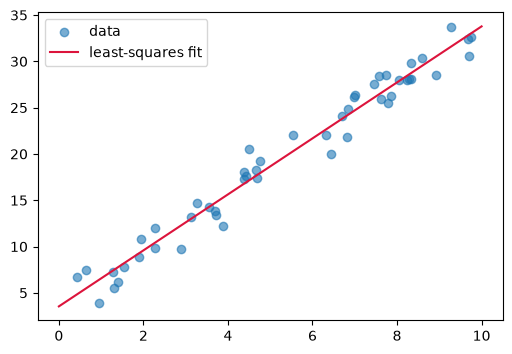

In [12]:
n = 50
x1 = rng.uniform(0, 10, n)
y_obs = 3.0 * x1 + 4.0 + rng.normal(0, 2.0, n)      # true slope 3, intercept 4, plus noise

X_design = np.column_stack([np.ones(n), x1])         # shape (50, 2): [1, x]
w_hat, *_ = np.linalg.lstsq(X_design, y_obs, rcond=None)   # lstsq returns several things; we want the first
print("estimated [intercept, slope]:", w_hat)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x1, y_obs, alpha=0.6, label="data")
xs = np.linspace(0, 10, 100)
ax.plot(xs, w_hat[0] + w_hat[1] * xs, color="crimson", label="least-squares fit")
ax.legend(); plt.show()

We'll derive this properly, and also solve it with gradient descent, in Module 07.

## 9. Preview: eigenvectors (optional on first read)

A matrix transforms vectors: it rotates and stretches them. An **eigenvector** of a square matrix `A` is a
special direction that `A` only *stretches*, without rotating it:

$$ A v = \lambda v $$

The stretch factor $\lambda$ is the **eigenvalue**. In PCA (Module 16), the eigenvectors of the data's covariance
matrix point along the directions in which the data varies most.

In [13]:
A = np.array([[3.0, 1.0],
              [1.0, 2.0]])
eigvals, eigvecs = np.linalg.eig(A)        # eigenvectors are the COLUMNS of eigvecs
v0 = eigvecs[:, 0]
print("eigenvalues:", eigvals)
print("A @ v0     :", A @ v0)
print("lambda * v0:", eigvals[0] * v0)     # same vector -> v0 is only stretched

eigenvalues: [3.618+0.j 1.382+0.j]
A @ v0     : [3.078+0.j 1.902+0.j]
lambda * v0: [3.078+0.j 1.902+0.j]


## Common pitfalls
- **Using `*` when you meant `@`.** `*` is element-wise and `@` is matrix multiplication.
- **Shape mismatches.** Before every `@`, say the shapes out loud: `(n, d) @ (d,)`. The inner numbers must match.
- **Using `np.linalg.inv` to solve systems.** Use `np.linalg.solve` (square systems) or `np.linalg.lstsq` (least squares) instead.
- **Duplicated or derived features.** These make `X.T @ X` singular or unstable.

## Recap
| Concept | NumPy | Why ML cares |
|---|---|---|
| dot product | `w @ x` | prediction of a linear model |
| norm / distance | `np.linalg.norm(u - v)` | KNN, k-means, regularization |
| matrix–vector | `X @ w` | predictions for all samples |
| shape rule | `(n,k)@(k,m)->(n,m)` | debugging 90% of errors |
| solve / lstsq | `np.linalg.solve`, `np.linalg.lstsq` | linear regression |
| eigenvectors | `np.linalg.eig` | PCA |

## 📚 Further resources
🎥 video · 📖 book or guide · 📄 paper. Watching the videos alongside the lesson is the best way to use them.

- 🎥 [Essence of Linear Algebra, chapters 1–4, 9 and 14 (3Blue1Brown) — highly recommended](https://www.youtube.com/playlist?list=PLZHQObOWTQDPD3MizzM2xVFitgF8hE_ab)
- 🎥 [Dot products and duality (3Blue1Brown)](https://www.youtube.com/watch?v=LyGKycYT2v0)
- 📖 [*Mathematics for Machine Learning*, chapters 2–3 (free PDF)](https://mml-book.github.io/)